In [6]:
import numpy as np

## Рекомендательные системы


### Содержание

* Определение и виды рекомендательных систем. 
* Методы коллаборативной фильтрации 
    * Метрические методы
    * Методы на основе матричных разложений
    * Линейные методы
    * Нейросетевая коллаборативная фильтрация
* Методы на основе контента 
* Гибридные рекомендательные системы 
* Метрики качества
* Cхемы валидации 

### Рекомендательные системы

<b>Рекомендательные системы </b> $-$ это системы фильтрации информации, предоставляющие пользователю (user) $u_i \in U$ персонализированную рекомендацию по объектам (item) $i_i \in I$ сервиса, на основе хранимых сервисом данных о его пользователях и объектах. 

<b>Примеры</b>

<script src="https://cdn.jsdelivr.net/npm/bootstrap@5.3.2/dist/js/bootstrap.bundle.min.js" integrity="sha384-C6RzsynM9kWDrMNeT87bh95OGNyZPhcTNXj1NW7RuBCsyN/o0jlpcV8Qyq46cDfL" crossorigin="anonymous"></script>
<div class="col-3">
    
<table class="table-sm table-bordered">
     <thead>
    <tr>
      <th scope="col">Сервис</th>
      <th scope="col">База данных о фильмах</th>
      <th scope="col">Интернет-магазин</th>
      <th scope="col">Музыкальный сервис</th>
    </tr>
  </thead>
<tr> <td>Объекты</td> <td>Фильмы</td> <td>Товары</td> <td>Песни</td>  </tr>    
</table>
</div>    





### Зачем рекомендации пользователю?

Рекомендательные системы обеспечивают:
* Отвечающий потребностям пользователя контент 
* Экономию времени на поиск контента
* Снижение интенсивности коммуникации с клиентом
* Открытие для пользователя новых типов контекта

### Зачем рекомендации сервису?

Рекомендательные системы обеспечивают:

* Увелинение целевых метрик сервиса:
    * Увеличение количества заказов и подписок, просмотров
    * Увеличение уводлетворенности пользователя 
    * Увеличение удолетворенности производителей контента
    * Увеличение длины сессии пользователя 
* Экономия на коммуникациях
* Дополнительных канал продаж 


### Подзадачи рекомендаций 

1. User2Item 
2. User2bundle: Рекомендовать пользователю набор товаров 
3. Users2Item: Рекомендации группе людей
4. Item2Item: С этим товаром обычно берут 
5. User2User: Возможно вам итересно будет познакомиться с 
6. Item2User: Пользовательский сегмент товара

### Какие данные использует рекомендательная система?

<b>Рекомендательные системы </b> $-$ это системы фильтрации информации, предоставляющие пользователю (user) $u_i \in U$ персонализированную рекомендацию по объектам (item) $i_i \in I$ сервиса, <b>на основе хранимых сервисом данных о его пользователях и объектах. </b>

Данные исопльзуемые рекоментадельными системами:
* Данные о взаимодействии пользователей и объектов
* Данные о пользователях 
* Данные об объектах 

### Какие данные использует рекомендательная система?

<b>Пример на данных музыкального сервиса:</b>

* Данные о взаимодействии пользователей и объектов:
    * какие песни оценил пользователь $-$ явная обратная связь
    * какие песни прослушал пользователь $-$ неявная обратная связь
    
    
* Данные о пользователях 
    * пол, возраст, дата регистрации на сервисе
    * любимые жанры и авторы музыки пользователя
    * через какую версию клиента пользователь взаимодействует с сервисом в момент запроса рекомендаций
    
    
* Данные об объектах 
    * Какой длительности, жанра музыкальный трек
    * Какое количество лайков и прослушиваний у данного музыкального трека
    * Кто автор трека

### Виды рекомендательных систем 

Типология рекомендательных систем в зависимости от используемых ими данных:

* Методы коллаборативной фильтрации $-$ используют только данные о взаимодействии пользователей и объектов
    * Метрические методы
    * Методы на основе матричных разложений
    * Линейные методы
    * Нейросетевая коллаборативная фильтрация
* Методы на основе контента $-$ используют данные о пользователях и объектах 
* Гибридные рекомендательные системы $-$ используют данные о пользователях, объектах и их взаимодействии

### Матрица взаимодействия пользователей и объектов $R_{m,n}$

<script src="https://cdn.jsdelivr.net/npm/bootstrap@5.3.2/dist/js/bootstrap.bundle.min.js" integrity="sha384-C6RzsynM9kWDrMNeT87bh95OGNyZPhcTNXj1NW7RuBCsyN/o0jlpcV8Qyq46cDfL" crossorigin="anonymous"></script>

<table class="table">
  <caption></caption>
    
  <thead>
    <tr>
      <th scope="col">#</th>
      <th scope="col">Бег</th>
      <th scope="col">Идиот</th>
      <th scope="col">Мимино</th>
      <th scope="col">Покровские ворота</th>
      <th scope="col">Римские каникулы</th>
    </tr>
  </thead> 
  <tbody>
    <tr>
      <th scope="row">1</th>
      <td>3</td>
      <td></td>
      <td></td>
      <td>7</td>
      <td>9</td>
    </tr>
    <tr>
      <th scope="row">2</th>
      <td>8</td>
      <td>9</td>
      <td>6</td>
      <td>4</td>
      <td>6</td>
    </tr> 
    <tr>
      <th scope="row">3</th>
      <td>9</td>
      <td>8</td>
      <td>4</td>
      <td></td>
      <td>5</td>
    </tr> 
    <tr>
      <th scope="row">4</th>
      <td></td>
      <td></td>
      <td>5</td>
      <td>7</td>
      <td>7</td>
    </tr> 
    <tr>
      <th scope="row">5</th>
      <td>8</td>
      <td>8</td>
      <td></td>
      <td>3</td>
      <td></td>
    </tr>
  </tbody>
    
</table>


$m \space -$ количество пользователей $N(u)$,

$n \space -$ количество объектов item'ов $N(i)$,


### Неперсонализированные подходы к рекомендациям

* Популярное за определенный период

$$Popularity(i)^{\Delta T} = \frac{  interactions_i^{\Delta T}}{ \sum_i^n  interaction_i^{\Delta T}}$$

* Новое


### Коллаборативная фильтрация. Метрический метод. 


<script src="https://cdn.jsdelivr.net/npm/bootstrap@5.3.2/dist/js/bootstrap.bundle.min.js" integrity="sha384-C6RzsynM9kWDrMNeT87bh95OGNyZPhcTNXj1NW7RuBCsyN/o0jlpcV8Qyq46cDfL" crossorigin="anonymous"></script>

<table class="table">
  <caption>Матрица взаимодействия пользователей и объектов</caption>
    
  <thead>
    <tr>
      <th scope="col">#</th>
      <th scope="col">Бег</th>
      <th scope="col">Идиот</th>
      <th scope="col">Мимино</th>
      <th scope="col">Покровские ворота</th>
      <th scope="col">Римские каникулы</th>
    </tr>
  </thead> 
  <tbody>
    <tr>
      <th scope="row">1</th>
      <td>3</td>
      <td></td>
      <td></td>
      <td>7</td>
      <td>9</td>
    </tr>
    <tr>
      <th scope="row">2</th>
      <td>8</td>
      <td>9</td>
      <td>6</td>
      <td>4</td>
      <td>6</td>
    </tr> 
    <tr>
      <th scope="row">3</th>
      <td>9</td>
      <td>8</td>
      <td>4</td>
      <td></td>
      <td>5</td>
    </tr> 
    <tr>
      <th scope="row">4</th>
      <td></td>
      <td></td>
      <td>5</td>
      <td>7</td>
      <td>7</td>
    </tr> 
    <tr>
      <th scope="row">5</th>
      <td>8</td>
      <td>8</td>
      <td></td>
      <td>3</td>
      <td></td>
    </tr>
  </tbody>
    
</table>

### Коллаборативная фильтрация. Метрический метод. 

<script src="https://cdn.jsdelivr.net/npm/bootstrap@5.3.2/dist/js/bootstrap.bundle.min.js" integrity="sha384-C6RzsynM9kWDrMNeT87bh95OGNyZPhcTNXj1NW7RuBCsyN/o0jlpcV8Qyq46cDfL" crossorigin="anonymous"></script>

<table class='table'>
  <caption>Матрица взаимодействия пользователей и объектов</caption>
  <thead>
    <tr>
      <th scope="col">#</th>
      <th scope="col">Бег</th>
      <th scope="col">Идиот</th>
      <th scope="col">Мимино</th>
      <th scope="col">Покровские ворота</th>
      <th scope="col">Римские каникулы</th>
    </tr>
  </thead> 
  <tbody>
    <tr>
      <th scope="row">1</th>
      <td>3</td>
      <td></td>
      <td></td>
      <td>7</td>
      <td>9</td>
    </tr>
    <tr>
      <th scope="row" class="bg-success">2</th>
      <td class="bg-success">8</td>
      <td class="bg-success">9</td>
      <td class="bg-success">6</td>
      <td class="bg-success">4</td>
      <td class="bg-success">6</td>
    </tr> 
    <tr>
      <th scope="row" class="bg-success">3</th>
      <td class="bg-success">9</td>
      <td class="bg-success">8</td>
      <td class="bg-success">4</td>
      <td class="bg-success"></td>
      <td class="bg-success">5</td>
    </tr>
    <tr>
      <th scope="row">4</th>
      <td></td>
      <td></td>
      <td>5</td>
      <td>7</td>
      <td>7</td>
    </tr> 
    <tr>
      <th scope="row" class="bg-info">5</th>
      <td class="bg-info">8</td>
      <td class="bg-info">8</td>
      <td class="bg-info"></td>
      <td class="bg-info">3</td>
      <td class="bg-info"></td>
    </tr>
  </tbody>
</table>

Как найти ближайших соседей для пользователя 5?

Как для пользователя 5 оценить рейтинг для фильма "Мимино" на основе ближайших соседей?

### Коллаборативная фильтрация. Метрический метод. 

<script src="https://cdn.jsdelivr.net/npm/bootstrap@5.3.2/dist/js/bootstrap.bundle.min.js" integrity="sha384-C6RzsynM9kWDrMNeT87bh95OGNyZPhcTNXj1NW7RuBCsyN/o0jlpcV8Qyq46cDfL" crossorigin="anonymous"></script>

<table class='table'>
  <caption>Матрица взаимодействия пользователей и объектов</caption>
  <thead>
    <tr>
      <th scope="col">#</th>
      <th scope="col">Бег</th>
      <th scope="col">Идиот</th>
      <th scope="col">Мимино</th>
      <th scope="col">Покровские ворота</th>
      <th scope="col">Римские каникулы</th>
    </tr>
  </thead> 
  <tbody>
    <tr>
      <th scope="row" class="bg-success">2</th>
      <td class="bg-success">8</td>
      <td class="bg-success">9</td>
      <td class="bg-success">6</td>
      <td class="bg-success">4</td>
      <td class="bg-success">6</td>
    </tr> 
    <tr>
      <th scope="row" class="bg-success">3</th>
      <td class="bg-success">9</td>
      <td class="bg-success">8</td>
      <td class="bg-success">4</td>
      <td class="bg-success"></td>
      <td class="bg-success">5</td>
    </tr>
    <tr>
      <th scope="row" class="bg-info">5</th>
      <td class="bg-info">8</td>
      <td class="bg-info">8</td>
      <td class="bg-info"></td>
      <td class="bg-info">3</td>
      <td class="bg-info"></td>
    </tr>
  </tbody>
</table>

<b>Как найти ближайших соседей для пользователя 5? </b>

Используем вектора оценок пользователей для их признакового описания. 

$\vec{u_5} = \left[8,8, nan, 3, nan \right]$

$\vec{u_2} = \left[8,9, 6, 4, 6 \right]$

$\vec{u_3} = \left[9,8, 4, nan, 5 \right]$

Для определения метрики близости выберем косинусное расстояние между векторами, рассчитанное по известным координатам:

$$cos(u_i, u_j) = \frac{\vec{u_i} \cdot \vec{u_j}}{|\vec{u_i}||\vec{u_j}|}$$

### Коллаборативная фильтрация. Метрический метод. 

<script src="https://cdn.jsdelivr.net/npm/bootstrap@5.3.2/dist/js/bootstrap.bundle.min.js" integrity="sha384-C6RzsynM9kWDrMNeT87bh95OGNyZPhcTNXj1NW7RuBCsyN/o0jlpcV8Qyq46cDfL" crossorigin="anonymous"></script>

<table class='table'>
  <caption>Матрица взаимодействия пользователей и объектов</caption>
  <thead>
    <tr>
      <th scope="col">#</th>
      <th scope="col">Бег</th>
      <th scope="col">Идиот</th>
      <th scope="col">Мимино</th>
      <th scope="col">Покровские ворота</th>
      <th scope="col">Римские каникулы</th>
    </tr>
  </thead> 
  <tbody>
    <tr>
      <th scope="row" class="bg-success">2</th>
      <td class="bg-success">8</td>
      <td class="bg-success">9</td>
      <td class="bg-success">6</td>
      <td class="bg-success">4</td>
      <td class="bg-success">6</td>
    </tr> 
    <tr>
      <th scope="row" class="bg-success">3</th>
      <td class="bg-success">9</td>
      <td class="bg-success">8</td>
      <td class="bg-success">4</td>
      <td class="bg-success"></td>
      <td class="bg-success">5</td>
    </tr>
    <tr>
      <th scope="row" class="bg-info">5</th>
      <td class="bg-info">8</td>
      <td class="bg-info">8</td>
      <td class="bg-info"></td>
      <td class="bg-info">3</td>
      <td class="bg-info"></td>
    </tr>
  </tbody>
</table>

<b>Рассчет косинусного расстояния между векторами пользователей $\vec{u_5}$ и $\vec{u_3}$</b>


$\vec{u_5} = \left[8,8, nan, 3, nan \right]$

$\vec{u_3} = \left[9,8, 4, nan, 5 \right]$

Для определения метрики близости выберем косинусное расстояние между векторами, рассчитанное по известным координатам:

$$cos(u_5, u_3) = \frac{\vec{u_5} \cdot \vec{u_3}}{|\vec{u_5}||\vec{u_3}|}= \frac{8\cdot 9 + 8 \cdot 8}{\sqrt{8^2 +8^2}\sqrt{9^2 +8^2}} = 0.998$$

### Коллаборативная фильтрация. Метрический метод. 

<script src="https://cdn.jsdelivr.net/npm/bootstrap@5.3.2/dist/js/bootstrap.bundle.min.js" integrity="sha384-C6RzsynM9kWDrMNeT87bh95OGNyZPhcTNXj1NW7RuBCsyN/o0jlpcV8Qyq46cDfL" crossorigin="anonymous"></script>

<table class='table'>
  <caption>Матрица взаимодействия пользователей и объектов</caption>
  <thead>
    <tr>
      <th scope="col">#</th>
      <th scope="col">Бег</th>
      <th scope="col">Идиот</th>
      <th scope="col">Мимино</th>
      <th scope="col">Покровские ворота</th>
      <th scope="col">Римские каникулы</th>
    </tr>
  </thead> 
  <tbody>
    <tr>
      <th scope="row" class="bg-success">2</th>
      <td class="bg-success">8</td>
      <td class="bg-success">9</td>
      <td class="bg-success">6</td>
      <td class="bg-success">4</td>
      <td class="bg-success">6</td>
    </tr> 
    <tr>
      <th scope="row" class="bg-success">3</th>
      <td class="bg-success">9</td>
      <td class="bg-success">8</td>
      <td class="bg-success">4</td>
      <td class="bg-success"></td>
      <td class="bg-success">5</td>
    </tr>
    <tr>
      <th scope="row" class="bg-info">5</th>
      <td class="bg-info">8</td>
      <td class="bg-info">8</td>
      <td class="bg-danger">5</td>
      <td class="bg-info">3</td>
      <td class="bg-info"></td>
    </tr>
  </tbody>
</table>

<b>Как для пользователя $u_5$ оценить рейтинг для фильма "Мимино" на основе ближайших соседей?</b>

Отберем два ближайших соседа по косинусному расстоянию от пользователя $u_5$ и усредним их оценки выставленные фильму "Мимино"

$$\hat{r}_{ui} = \frac{\sum_{j \in N(u)} r_{ji}}{|N(u)|}$$


$$\hat{r}_{5,Мимино} = \frac{\sum_{j \in \{2,3\}} r_{j,Мимино}}{|\{2,3\}|}= \frac{6+4}{2}=5$$


### Коллаборативная фильтрация. Метрический метод. 

Для того, чтобы сформировать для пользователя $u_i$ персональные рекомендации на основе похожих на него пользователей нужно пройти следующие шаги:

1. Выборать метрику близости просизвести её рассчет. 
2. Выборать $k$ ближайших сосдедей для пользователя $u_i$.
3. Рассчитать оценки объектов для $u_i$ на основе известных оценок соседей.
4. Отсортировать объекты по убыванию оценок и вернуть пользователю $n$ самых релевантных, высокорейтинговых. 


### Коллаборативная фильтрация. Достоинства и недостатки. 

<table class='table'>
  <thead>
    <tr>
      <th scope="col">Достоинства</th>
      <th scope="col">Недостатки</th>
    </tr>
  </thead> 
  <tbody>
    <tr>
      <td>Простота реализации</td> <td>Нужны оценки пользователей</td>
    </tr>
     <tr>
      <td>Интерпретируемость</td> <td>Невозможность предсказания для новго пользователя</td>
    </tr>  
    <tr>
      <td>Низкая вычислительная сложность</td>  <td>Невозможность предсказания для новго объекта</td>
    </tr>
    <tr>
      <td>Легкость добавления новых объектов и пользователей</td> <td></td>
    </tr>
    </tbody> 
    </table>

### Коллаборативная филтрация. Метод на основе разложения матрицы.

Допустим оценку объекта пользователем $r_{ui}$ можно представить в следующем виде:

$$\hat{r}_{ui} = \mu + b_u + b_i$$

$\mu \space - $ средняя оценка объектов 

$b_u \space - $ смещение пользователя 

$b_i \space - $ смещение объекта 

Представим, что мы уже получили оценку объекта $i$ пользователем $u$, тогда оценить ошибку нашего предсказания можно с помощью функции $L$:

$$L(u,i) = \left(r_{ui} - \hat{r}_{ui} \right)^2$$ 


Научившись измерять ошибку предсказания мы должны <b>по данным матрицы взаимодействия подобрать такие коэффициенты $b_u$ и $b_i$, чтобы минимизировать ошибку предсказания оценки $r_{ui}$</b>

$$\sum_{(i,u)} \left(r_{ui} - \mu - b_u - b_i \right)^2  \rightarrow \min_{b_u, b_i}$$

### Коллаборативная филтрация. Метод на основе разложения матрицы. 

Модель: 

$$r_{ui} = \mu + b_u + b_i + q_u^Tq_i$$

$\mu - $ средняя оценка объектов 

$b_u - $ смещение пользователя 

$b_i - $ смещение объекта 

$q_u - $ вектор пользователя 

$q_i - $ вектор объекта

<b>По данным матрицы взаимодействия подобрать такие коэффициенты $b_u$, $b_i$ и вектора $q_u$, $q_i$, индивидуальные для каждого пользователя и фильма, чтобы минимизировать ошибку предсказания оценки $r_{ui}$</b>

$$\sum_{(i,u)} \left(r_{ui} - \mu - b_u - b_i - q_u^Tq_i\right)^2  \rightarrow \min_{b_u, b_i, q_u, q_i}$$

### [SLIM. Sparse Linear Methods for Top-N Recommender Systems](https://www.researchgate.net/publication/220765374_SLIM_Sparse_Linear_Methods_for_Top-N_Recommender_Systems) 

$$\tilde{r}_{uj} = \sum^n_{i}r_{ui} w_{ij} = r_u^Tw_j, \space \space w_{jj} = 0 $$

т.е. для каждого item'а учится вектор его схожести с другими item'ами. $w_{ij} -$ мера схожести item'ов $i$ и $j$ 

##### Матричный вид

$$\frac{1}{2}||R - RW||^2_F + \frac{\beta}{2} ||W||^2_F + \lambda ||W||_1   \rightarrow \min_{W} $$
$$ s.t. w_{ii} = 0, w_{ij} \ge 0 $$
$W_{n,n}$ - матрица весов модели имеет $n^2 - n$ параметров, $n$ это количество объектов item'ов

##### Разделение переменных

Можно представить как $n$ независимых задач оптимизации для каждого объекта (item'а), каждого столбца матрицы $W$:

$$\frac{1}{2}||r_j - Rw_j||^2_F + \frac{\beta}{2} ||w_j||^2_F + \lambda ||w_j||_1   \rightarrow \min_{w_j} $$
$$ s.t. w_{jj} = 0, w_{ij} \ge 0 $$

$r_j$ - столбец матрицы взаимодействия, характеризующий  item

$w_j$ - столбец матрицы весов

т.е. вектор каждого item'а неотрицательная линейная комбинация векторов других item'ов 

<b>Почему бы не сделать матрицу W симметричной? это снизит количество весов вдвое и логично ведь насколько i похож на j настолько и j похож на i </b>

### [SLIM. Sparse Linear Methods for Top-N Recommender Systems](https://www.researchgate.net/publication/220765374_SLIM_Sparse_Linear_Methods_for_Top-N_Recommender_Systems) 


$$\frac{1}{2}||R^T - R^TW||^2_F + \frac{\beta}{2} ||W||^2_F + \lambda ||W||_1   \rightarrow \min_{W} $$
$$ s.t. w_{ii} = 0, w_{ij} \ge 0 $$

$W_{m,m}$ - матрица весов модели имеет $m^2 - m$ параметров, $m$ - количество пользователей. 

Можно представить как $m$ независимых задач оптимизации для каждого пользователя, каждого столбца матрицы $W$:

$$\frac{1}{2}||r_u - R^Tw_u||^2_F + \frac{\beta}{2} ||w_u||^2_F + \lambda ||w_u||_1   \rightarrow \min_{w_u} $$
$$ s.t. w_{uu} = 0, w_{uj} \ge 0 $$

$r_u$ - строка исходной матрицы взаимодействия $R$, характеризающая пользователя

$w_j$ - столбец матрицы весов

т.е. вектор каждого пользователя неотрицательная линейная комбинация векторов других пользователей

### Зачем нужен SLIM ?


<table class="table">
  <caption>Movielens 1M</caption>
    
  <thead>
    <tr>
      <th scope="col">#</th>   
      <th scope="col">HR@5</th>
      <th scope="col">NDCG@5</th>
      <th scope="col">HR@10</th>
      <th scope="col">NDCG@10</th>
    </tr>
  </thead> 
  <tbody>
    <tr>
      <th scope="row">TopPopular</th>
      <td>0.3043 </td>
      <td>0.2062</td>
      <td>0.4531</td>
      <td>0.2542</td>
    </tr> 
    <tr>
      <th scope="row">UserKNN</th>
      <td>0.4916</td> 
      <td>0.3328</td>
      <td>0.6705</td>
      <td>0.3908</td>
    </tr>  
    <tr>
      <th scope="row">ItemKNN</th>
      <td>0.4829 </td> 
      <td>0.3328</td>
      <td>0.6596</td>
      <td>0.3900</td>
    </tr>  
    <tr>
      <th scope="row">$P^3\alpha$</th>
      <td>0.4829 </td> 
      <td>0.3328</td>
      <td>0.6596</td>
      <td>0.3900</td>
    </tr>    
   <tr>
      <th scope="row">$RP^3\beta$</th>
      <td>0.4922 </td> 
      <td>0.3409</td>
      <td>0.6715</td>
      <td>0.39910</td>
    </tr> 
      <tr>
      <th scope="row">NeuMF</th>
      <td>0.5486</td>  
      <td>0.3840</td>
      <td>0.7120</td>
      <td>0.4369</td>
    </tr> 
         <tr>
      <th scope="row" class="bg-info">SLIM</th>
      <td class="bg-info">0.5589</td>  
      <td class="bg-info">0.3961</td>
      <td class="bg-info">0.7161</td>
      <td class="bg-info">0.4470</td>
    </tr> 
   </tbody>
</table>

[Статья Are We Really Making Much Progress?](https://arxiv.org/pdf/1907.06902)

### EASE. [Embarrassingly Shallow Autoencoders for Sparse Data](https://arxiv.org/pdf/1905.03375)


$$||R - RW||^2_F + \lambda ||W||^2_F  \rightarrow \min_{W} $$
$$ s.t. w_{ii} = 0$$
$W_{n,n}$ - матрица весов модели имеет $n^2 - n$ параметров, $n$ это количество объектов item'ов

Выпуклая задача оптимизации имеющая явное аналитическое решение:

$$\tilde{P} = (R^TR + \lambda I)^{-1}$$

$$W_{ij} = 
\begin{cases}
0, i = j\\ 
-\frac{\tilde{P}_{ij}}{\tilde{P}_{jj}}, иначе\\
\end{cases}
$$

### EASE. [Embarrassingly Shallow Autoencoders for Sparse Data](https://arxiv.org/pdf/1905.03375)

Достоинства модели:

* Имеет аналитическое решение
* Можно один раз обучить матрицу $W$ и использовать ее на разных пользователях
* Имеет всего один гиперпараметр
* Устойчив к варьированию гиперпараметра (в отличие от SLIM)
* Улучшает качество при добавлении редких item'ов
* При обновлении вектора оценок пользователя можно не обновлять матрицу $W$
* Может спокойно работать в онлайне при latency 50 мс под нагрузкой 200 rps с ~10к каталогом
* Можно искать похожие item'ы через его матрицу $W$


Недостатки модели: 

* $O(n^3)$ – сложность вычисления обратной матрицы. Убраем непопулярные item'ы, смотрим на модификации SARSA, ELSA
* Не учитывает последовательность взаимодействий. Смотрим модификацию SLIST

### Зачем нужен EASE ?


<table class="table">
  <caption>Quality results on the MSD benchmark sorted by Recall@20 scores</caption>  
  <thead>
    <tr>
      <th scope="col">#</th>   
      <th scope="col">Recall@20</th>
      <th scope="col">Recall@50</th>
      <th scope="col">NDCG@100</th>
    </tr>
  </thead> 
  <tbody>
    <tr>
      <th scope="row" class="bg-info">EASE</th>
      <td class="bg-info">0.333</td> 
      <td class="bg-info">0.428</td>
      <td class="bg-info">0.389</td>
    </tr> 
    <tr>
      <th scope="row">iALS</th>
      <td>0.309</td> 
      <td>0.415</td>
      <td>0.368</td>
    </tr>  
    <tr>
      <th scope="row">RecVAE</th>
      <td>0.276 </td>  
      <td>0.374</td>
      <td>0.326</td>
    </tr>  
    <tr>
      <th scope="row">RaCT</th>
      <td>0.268</td>  
      <td>0.364</td>
      <td>0.319</td>
    </tr>    
   <tr>
      <th scope="row">LambdaNet</th>
      <td>0.259</td> 
      <td>0.355</td>
      <td>0.308</td>
    </tr> 
      <tr>
      <th scope="row">Popularity</th>
      <td>0.043</td>   
      <td>0.068</td>
      <td>0.058</td>
    </tr> 
   </tbody>
</table>


[Статья Revisiting the Performance of iALS on Item Recommendation Benchmarks, 2021](https://arxiv.org/pdf/2110.14037)

### SVD - сингулярное разложение 

**Теорема** Любая матрица $A\in \mathbb{C}^{n\times m}$ может быть представлена в виде произведения трёх матриц:  

$$
   A = U \Sigma V^*,
$$

где 

$U$ – унитарная  матрица $n \times K$,

$V$ – унитарная матрица $m \times K$, $K = \min(m, n)$,

$\Sigma$ – диагональная матрица с неотрицательными элементами на диагонали $\sigma_1 \geq  \ldots, \geq \sigma_K$. 

Более того, если $\text{rank}(A) = r$, тогда $\sigma_{r+1} = \dots = \sigma_K = 0$.

### Теорема Eckart'a-Young'a

Наилучшая малоранговая аппроксимация может быть вычислена с помощью SVD.

**Теорема:** Пусть $r < \text{rank}(A)$, $A_r = U_r \Sigma_r V_r^T$. Тогда

$$
    \min_{\text{rank}(B)=r} \|A - B\|_F = \|A - A_r\|_F = \sqrt{\sigma_{r+1}^2 + \dots + \sigma_{\min (n,m)}^2}.
$$


### Пример

In [93]:
n, m = 20, 10
X = np.array([[1.0/(i + j + 0.5) for i in range(m)] for j in range(n)])
# mask = np.random.binomial(1, 0.1, (n,n))
u, s, vt = np.linalg.svd(X)

In [96]:
X.shape, u.shape, vt.shape, s.shape

((20, 10), (20, 20), (10, 10), (10,))

In [97]:
r = 2
u = u[:, :r]
s = s[:r]
vt = vt[:r, :] 

In [98]:
X_appr = u.dot(np.diag(s).dot(vt))
error = np.linalg.norm(X_appr - X, 'fro') / np.linalg.norm(X, 'fro')

In [99]:
error

0.034240727014879534

In [100]:
u.shape, vt.shape, s.shape

((20, 2), (2, 10), (2,))

Мы с точность 3,4% приблизили исходную матрицу $X$ размерности $20 \times 10$ призведением двух матриц:
- $U_r$  размерности $20 \times 2$
- $\Sigma_r V_r^T$ размерности $2 \times 10$ 

### Коллаборативная фильтрация. Матричная факторизация.

Аппроксимируем матрицу взаимодействий $R$ произведением двух матриц $ UI^T$. Таким образом:

* Матрица взаиомдействий $ R_{m, n} $ <br>
* Матрица эмбеддингов пользователей $P_{m \times r}$, где строка $p_u$ - это эмбеддинг пользователя $u$. <br>
* Матрица эмбеддингов item'ов $Q_{n \times r}$, где строка $q_j$ - это эмбеддинг item'a $j$.

$$\sum_{(i,u)} \left(r_{ui} - p_uq_i^T\right)^2  \rightarrow \min_{Q, P}$$


### ALS

Итак, поставлена задача построения модели со скрытыми переменными (latent factor model) для коллаборативной фильтрации:

$$\sum_{u,i} (r_{ui} - p_uq_i^T)^2 \to \min_{P,Q}. $$


Подход ALS (Alternating Least Squares) минимизирует заданный функционал, попеременно фиксируя матрицы $P$ и $Q$, — оказывается, что, зафиксировав одну из матриц, можно выписать аналитическое решение задачи для другой.

$$\nabla_{p_u} \bigg[ \sum_{u,i} (r_{ui} - p_uq_i^T)^2 \bigg] = \sum_{i} 2(r_{ui} - p_uq_i^T)q_i = 0$$

Воспользовавшись тем, что $cb^Ta = a^Tbc $, получим
$$\sum_{i} r_{ui}q_i - \sum_i q_i^T q_i p_u = 0.$$
Тогда окончательно каждый столбец матрицы $P$ можно найти по формуле
$$p_u = \bigg( \sum_i q_i^T q_i\bigg)^{-1}\sum_ir_{ui}q_i \;\; \forall u,$$
Аналогично для столбцов матрицы $Q$
$$q_i = \bigg( \sum_u p_u^T p_u\bigg)^{-1}\sum_ur_{ui}p_u \;\; \forall i.$$

Таким образом мы можем решать оптимизационную задачу, поочередно фиксируя одну из матриц $P$ или $Q$ и проводя оптимизацию по второй.


### iALS

Модификация для неявной обратной связи:

$$\sum_{(i,u)} c_{ui}\left(x_{ui} - p_uq_i^T\right)^2 + \lambda \left( ||P||^2_F + ||Q||^2_F \right) \rightarrow \min_{Q, P}$$

$x_{ij} = 
\begin{cases}
1, r_{ij} > 0\\ 
0, r_{ij} \le 0 \space или \space r_{ij} \space - \space неопределено \\
\end{cases}
$

$c_{ui} = 1 + \alpha |r_{ij}|$ - степень уверенности в оценке $x_{ij}$

### Обобщение ALS

Модель: 

$$\tilde{r}_{ui} = \mu + b_u + b_i + p_uq_i^T$$

$\mu - $ средняя оценка объектов 

$b_u - $ смещение пользователя 

$b_i - $ смещение объекта 

$$\sum_{(i,u)} \left(r_{ui} - \mu - b_u - b_i - p_uq_i^T\right)^2  \rightarrow \min_{b_u, b_i, P, Q}$$

### NeuMF.  [Neural Collaborative Filtering](https://arxiv.org/pdf/1708.05031). 

<img src='https://images.deepai.org/converted-papers/2004.12212/images/NCF.png' width=500>




Нелинейным обобщением матричных разложений является коллаборативная фильтрация с помощью нейронных сетей.


Каждому пользователю $u$ ставится в соотвествие one-hot encode вектор, у которого на $u$-ом месте стоит $1$, а остальные координаты заполнены нулями, аналогично определим вектор $i$ для товара $i$. 


Два полносвязных слоя на входе: один соответствует пользователям и принимает на вход вектор $u$, а второй соответствует товарам и принимает на вход вектор $i$. 

После входных полносвязных слоев соответствующие представления необходимо сконкатенировать и передать в следующие полносвязные слои. На выходе нейронной сети мы получаем предсказание $\tilde{r}_{ui}$ (на рисунке обозначено как $\tilde{y}_{ui}$), которое сравниваем с истинным ответом для заданной пары $r_{ui}$ (на рисунке обозначен как $y_{ui}$).

Несмотря на свою простоту модель обладает рядом важных достоинств:

* мы можем легко обобщить модель на случай, когда у нас есть признаки пользователей или товаров, добавив эти признаки к векторам $u$ и $i$ соответственно (также заметим, что добавление признаков в модель позволяет частично решить проблему холодного старта);
* в зависимости от размеров выборки и природы данных мы можем адаптировать архитектуру под свои нужды, например, если у нас есть картинки в качестве признаков товаров, мы можем добавить сверточные слои в нашу нейронную сеть и обучать всю модель end-to-end.

В этой модели мы по-прежнему можем получить латентные представления пользователей и товаров. На самом деле, латентными представлениями будут столбцы матрицы весов в первых полносвязных слоях (в предположении, что мы умножаем матрицу весов на вектор признаков справа).

### Приближенный поиск соседей на основе эмбедингов

Приближенный поиск соседей можно организовать через ElasticSearch:
    
* [Introducing to approximate nearest neighbor search](https://www.elastic.co/blog/introducing-approximate-nearest-neighbor-search-in-elasticsearch-8-0)

* [Similarity Search and Similar Image Search in Elasticsearch](https://medium.com/@kumon/similarity-search-and-similar-image-search-in-elasticsearch-14552a8a8dea)

Фреймворки для поиска ближайших соседей: 

* [annoy от spotify](https://github.com/spotify/annoy)
* [nmslib](https://github.com/nmslib/nmslib)
* [hnswlib](https://github.com/nmslib/hnswlib)
* [faiss от facebook](https://github.com/facebookresearch/faiss)

[Бенчмарк методов](https://github.com/erikbern/ann-benchmarks)

### Контент и контекст 

<b>Идея:</b> использовать признаки объекта и пользователя, а так же условия при которых было совершено взаимодействие.

<b>Контент</b> – описательное свойство объекта/пользователя, которое, как
правило, не изменяется во времени или делает это очень редко.

* Описание товара
* Категория товара
* Пол пользователя
* Имя пользователя
* Режиссер фильма

<b>Контекст</b> – внешние условия или быстро меняющиеся признаки.

* Время
* Геолокация
* Девайс получения рекомендаций
* Количество денег на счету
* Поисковый запрос недавний


#### DSSM (Deep Structured Semantic Model) 

Оригинальная модель DSSM для задачи ранжирования выдачи поиска.  

<img src='https://kishorepv.github.io/images/DSSM_layers.png' width=700>

где $R(Q, D) = cosine(y_{Q}, y_{D}) = \dfrac{y_{Q}^{T} y_{D}}{||y_{Q}|| \cdot ||y_{D}||}$. 

При этом, считаем оценку семантической релевантности текущего документа и запроса как:

$$P(D|Q) = \frac{exp(\gamma \cdot R(Q, D))}{\sum_{D' \in D}exp(\gamma \cdot R(Q, D') }$$

$\gamma -$ сглаживающий коэффициент

Проблема со знаменателем давно известна, поэтому минимизировать будем следующую функцию:

$$L (Λ) = - log \prod_{(Q, D^{+})} P(D^{+}|Q)$$

### Ранжирование 


Дано: $X^l$ - обучающая выборка и $i ≺ j$ отношение $x_j лучше, чем x_i$ между объектами $X^l$

Найти ранжирующую функцию $a: X \rightarrow \mathbb{R}$ восстанавливающую правильное отношение порядка
$i ≺ j \rightarrow a(x_i) < a(x_j)$

Три подхода к функции потерь:
* Point-wise - поточечный (аналог регресии/классификации)
* Pair-wise - попарный (качество попарных сравнений)
* List-wise - списочный (качество ранжированного списка) lambdaRANK, lambdaMART

### Попарный подход 

Переход к гладкому функционалу ранжирвоания 

$$Q(X^l,w) = \sum_{i ≺ j} [a(x_j, w) - a(x_i,w) < 0]  $$


$$ \sum_{i ≺ j} L(a(x_j, w) - a(x_i,w)) \rightarrow \min_w $$

$L$ - убывающая непрерывная функция от отсупа $M = a(x_j, w) - a(x_i,w)$:

* $L(M) = (1 - M)_{+}$ - RankSVM
* $L(M) = exp(- M)$ - RankBoost
*  $L(M) = log(1 +  e^{-M})$ - RankNet

### Функция потерь

* **Кросс-энтропия**

$\hat p_{ui} = \sigma (R(u, i)) = \sigma(y_{u}^T y_{i})$ - вероятность, что юзер совершит действие с айтемом.

Тогда функция потерь:

$L = - \sum_{u, i} (r_{ui}\cdot log \hat p_{ui} + (1 - r_{ui}) \cdot log(1 - \hat p_{ui}))$

* **Triplet loss**

Рассматриваем тройки из пользователя, положительного примера для него и отрицательного - $R(u, i_{+}, i_{-})$

$L _{margin}(u,i,j)=max(0, margin + sim(u,i) − sim(u,j))$

То есть, пытаемся увеличивать разницу, задавая некоторый порог (отступ) альфа. 

Для pairwise лоссов: 

$L _{BPR}(u,i,j)= - log(\sigma(sim(u,i) − sim(u,j))$

### Матричная факторизация и DSSM
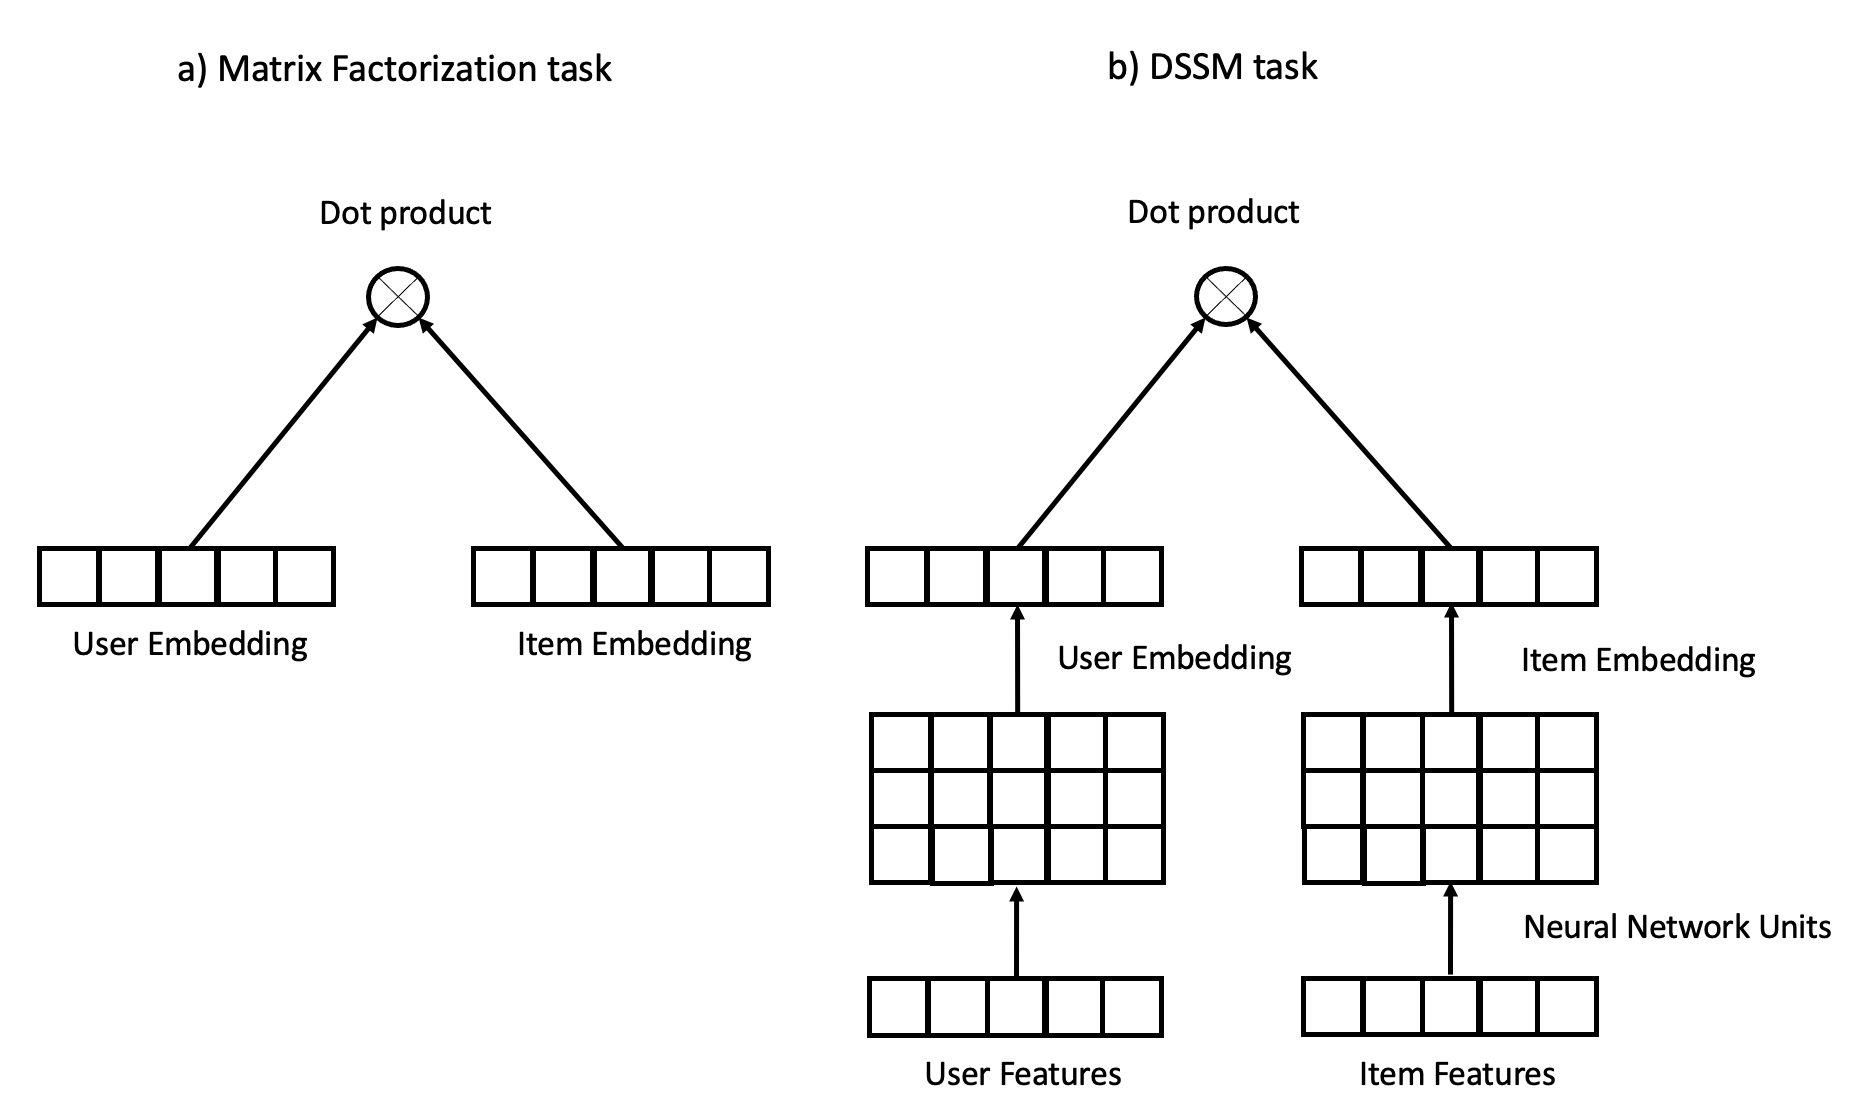

### YouTube
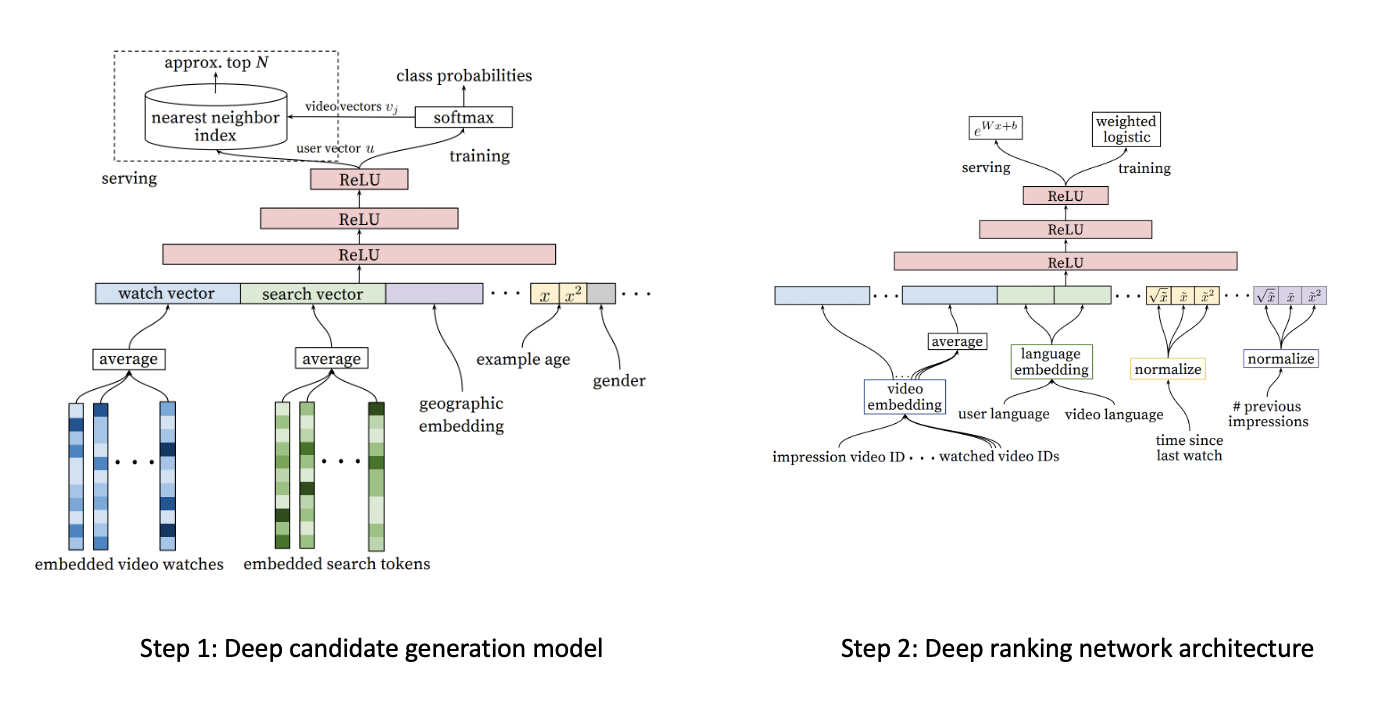

### Инструменты 

1. [RePlay](https://github.com/sberbank-ai-lab/RePlay) 60 звезд, 4 разработчика
2. [surprise](https://github.com/NicolasHug/Surprise) 6100 звезд, 40 разработчиков
3. [recmetrics](https://github.com/statisticianinstilettos/recmetrics) 550 звезд, 19 разработчиков
4. [DeepCTR](https://github.com/shenweichen/DeepCTR/tree/master) 7200 звезд, 14 разработчиков
5. [fastFM](https://github.com/ibayer/fastFM) 1100 звезд, 14 разработчиков
6. [lightFM](https://github.com/lyst/lightfm) 4500 звезд, 32 разработчика
7. [TensorFlow Recommenders](https://github.com/tensorflow/recommenders/tree/main) 1700 звезд, 33 разработчика
8. [TorchRec](https://github.com/pytorch/torchrec) 1600 звезд, 114 разработчиков
9. [implicit](https://github.com/benfred/implicit) 3300 звезд, 30 разработчиков
10. [RecBole](https://github.com/RUCAIBox/RecBole/) 3300 звезд, 51 разработчик
11. [Список инструментов](https://github.com/grahamjenson/list_of_recommender_systems)
12. [recommenders](https://github.com/recommenders-team/recommenders) 19000 звезд, 100 разработчиков
13. [monolith](https://github.com/bytedance/monolith) 8500 звезд, 3 разработчика

### Источники

1. [Курс рекомендательные системы, ВШЭ](https://github.com/anamarina/RecSys_course/tree/2023)

2. [Конференция RecSys](https://recsys.acm.org/)

3. [Курс Ваша первая рекомендательная система с нуля. МТС, ODS](https://ods.ai/tracks/mts-recsys-df2020)

4. [Курс Введение в машинное обучение 2019. К.В. Воронцов, ШАД, лекции 17,18](https://www.youtube.com/playlist?list=PLJOzdkh8T5krxc4HsHbB8g8f0hu7973fK)

5. [Specialization recommender system, University of Minnesota, Coursera](https://www.coursera.org/specializations/recommender-systems#courses)

6. [Building recommendation systems with TensorFlow, TensorFlow](https://youtube.com/playlist?list=PLQY2H8rRoyvy2MiyUBz5RWZr5MPFkV3qz&si=7ObYvQjVGbS-mwMp)

7. [Курс recommender systems, Universite de Montreal, edx](https://www.edx.org/learn/machine-learning/universite-de-montreal-recommender-systems-behind-the-screen)

8. [Статья Methodologies for Improving Modern Industrial Recommender Systems, Shusen Wang, 2023](https://arxiv.org/abs/2308.01204)

9. [Статья A Survey of Graph Neural Networks for Social Recommender Systems, 2022](https://arxiv.org/pdf/2212.04481v2.pdf)

10. [Статья Graph Neural Networks in Recommender Systems: A Survey, 2022](https://arxiv.org/pdf/2011.02260.pdf)

11. [Cтатья Active Matrix Factorization for Surveys, 2019, Berkeley, Facebook](https://arxiv.org/pdf/1902.07634.pdf)

12. [Телеграмм канал "ML - это ОК"](https://t.me/mlvok)

13. [Статья A Survey of Matrix Completion Methods for Recommendation Systems, 2018](https://core.ac.uk/download/pdf/217295558.pdf)

14. [Статья An Introduction to Matrix factorization and Factorization
Machines in Recommendation System, and Beyond, 2022](https://arxiv.org/pdf/2203.11026.pdf)

15. [A Survey of Recommendation Systems: Recommendation Models, Techniques, and Application Fields,Hyeyoung Ko
,2022](https://www.researchgate.net/publication/357568873_A_Survey_of_Recommendation_Systems_Recommendation_Models_Techniques_and_Application_Fields)

16. [Курс Рекомендательные системы, Н.Анохин, MADE](https://github.com/aamamaev/MADE_recsys/tree/master/slides)

17. [Курс Машинное обучение, Николенко, СПБГУ, 2019, лекции 12-13](https://logic.pdmi.ras.ru/~sergey/teaching/mlspsu2018.html)

18. [Статья Are We Really Making Much Progress? A Worrying Analysis of
Recent Neural Recommendation Approaches, 2019, Dacrema, Cremonesi](https://arxiv.org/pdf/1907.06902), [git](https://github.com/aamamaev/RecSys2019_DeepLearning_Evaluation)
19. [Статья Embarrassingly Shallow Autoencoders for Sparse Data, 2019, Harald Steck, Netflix](https://arxiv.org/pdf/1905.03375)
20. [Статья Revisiting the Performance of iALS on Item Recommendation Benchmarks, 2021, Rendle, Google](https://arxiv.org/pdf/2110.14037)
21. [Репозиторий с материалами по GNN Recommender Systems от tsinghua fib lab](https://github.com/tsinghua-fib-lab/GNN-Recommender-Systems)

### Разбиение на train-test.
0. Random Split. 
1. Leave one last - для каждого пользователя к тестовой выборке относим последний объект/сессию, c которым пользователь провзаимодействовал. 
2. Temporal split - временная отсечка отделяющая обучающую выборку от тестовой
  * global temporal - общая для всех отсечка $T_{split}$
  * user based - последние $\Delta t$ для каждого пользователя
  
3. User split - разбиение по пользователям

Представим, что на вопрос нашего воображаемого ds менеджер ответил "Чтобы повысить продажи". Вы уже знаете, что под продажами можно понимать все что угодно

И вроде бы в голове есть картинка:
1. Рекомендуем вот этот шкаф 
2. Юзеру нравится рекомендация 
3. Юзер приезжает к нам (заходит в интернет-магазин) и покупает его

Но опытные DS сразу увидят подвох:
* В нашем магазине у клиентов довольно мало покупок (вы часто покупаете холодильник или шкаф?)
* Очень сложно угадать конкретный предмет для рекомендаций

В общем, стандартный кейс для холодного старта

Поэтому, скорее всего, вы просто не сможете нормально обучить рекомендательную систему. Что же делать?

Давайте ещё раз зададим вопрос "А зачем? ", внимательно смотря на нашу схему:

1. Рекомендуем вот этот шкаф 
2. Юзеру нравится рекомендация 
3. Юзер приезжает к нам (заходит в интернет-магазин) и покупает его

Начнём с конца (3): "юзер .. покупает его". Нам точно нужно именно это? А если юзер купит не тот шкаф, что мы рекомендовали, а другой? Другой шкаф = тоже успех! Значит, нам нужно, чтобы юзер купил хоть что-то

Если нужно, чтобы он купил хоть что-то, но рекомендации хотим все ещё персональные, то мы можем рекомендовать не товар, а категорию товаров

А чтобы юзеру точно понравились рекомендации, можно дать ему небольшую скидку на категорию

И вот, наша рекомендация "шкаф такой-то", где мы очень вряд ли сможем угадать предпочтение пользователя, превратилась в "Скидка на шкафы 10%". Уже лучше, не правда ли? И нашу итоговую цель мы точно также достигаем

И получаем схему :
1. Рекомендуем вот этот шкаф  категорию и скидку на нее
2. Юзеру нравится рекомендация 
3. Юзер приезжает к нам (заходит в интернет-магазин) и покупает его хоть что-то

Вывод
Всегда спрашивайте, зачем вас просят что-то сделать. Очень вероятно, что вы найдёте более удачный способ добиться конечной цели

Во-вторых, мы сильно недооцениваем модель "рекомендуй самое популярное". У которой есть ещё куча вариаций вроде "самое популярное в каждой категории"

На самом деле во многих сервисах (в том же Нетфликс!) есть разделы вроде "Популярное", "Смотрят сейчас", "Новинки", которые строятся безо всякой персонализации! Но при этом эти рекомендации релевантный очень многим пользователям просто потому что они популярны

Если у вас бизнес, в котором юзер покупает один и тот же товар регулярно, то прекрасная персональная рекомендация - это рекомендовать то, что юзер уже покупал. Поверьте, такую "модель" рекомендаций очень сложно побить


3. Товары в сортировке должны быть разнообразными

Если вы выполнили первые 2 пункта, то это вас не спасёт от того, что топ-20 позиций в сортировке займёт хлеб. Может, хлеб и популярен, и действительно является хорошей рекомендаций, но не 20 же штук 😝

Обычно, чтобы такого не было, товары не сортируют по популярности, а сэмплируют с вероятностью пропорциональной популярности - проверено, работает


1. Precision@k — это количество релевантных объектов в топ-k делённое на k. 
$$P@k = \sum_{i=1}^k \frac{rel_i}{k}$$  $rel_i \in \{1,0\}$ 

2. Recall@k — доля релевантных, попавших в топ-k, от общего числа релевантных. То есть R@k = (число релевантных в топ-k) / (общее число релевантных). Обозначим общее количество релевантных элементов как R. Тогда P@k = (Σ_{i=1}^k rel_i) / k, a Recall@k = (Σ_{i=1}^k rel_i) / R. Нужно учесть, что если R = 0, то Recall@k не определен, но на практике это случаи без релевантных элементов, которые могут игнорироваться.



4. Average Precision (AP) — точнее, Average Precision для одного запроса вычисляется как среднее значение precision в точках, где встречаются релевантные документы. Формула AP = Σ_{k=1}^n (P@k * rel_k) / R, где R — общее число релевантных, rel_k — индикатор релевантности на позиции k. Но это если считать только в тех k, где документ релевантный. Иногда используют интерполяцию, но чаще AP определяется как сумма precisions в каждом релевантномоле, делённая на общее количество релевантных. Например, AP = (1/R) * Σ_{k=1}^n P@k * rel_k.

5. Mean Average Precision (MAP) — просто среднее AP по всем запросам. MAP = (1/Q) * Σ_{q=1}^Q AP(q), где Q — количество запросов.

6. DCG — Discounted Cumulative Gain. Обычно считается как Σ_{i=1}^k (rel_i / log_2(i + 1)) для позиций от 1 до k. Есть другой вариант, где для релевантности больше двух уровней используют 2^{rel_i} - 1, но чаще для бинарной релевантности просто rel_i. Например, DCG@k = Σ_{i=1}^k (rel_i / log_2(i + 1)). Иногда начинают с i=2, тогда знаменатель log(i + 1) — но нужно проверить стандартное определение. Иногда для первого элемента не дисконтируют, тогда i=1, log_2(1 + 1) = 1, так что разницы нет.

7. NDCG — это DCG, поделённый на идеальный DCG (IDCG). То есть NDCG@k = DCG@k / IDCG@k, где IDCG — это максимально возможный DCG при идеальном порядке релевантных объектов. Поэтому NDCG — это нормированный DCG, и его значение между 0 и 1.

8. MRR — Среднее обратного ранга первого правильного ответа. Для каждого запроса находим позицию первого релевантного элемента rank, затем берём 1/rank. MRR — среднее этого значения по всем запросам. То есть MRR = (1/Q) * Σ_{q=1}^Q 1/rank_q. Если нет релевантных элементов, возможно заменяют на 0, но точная формула предполагает, что хотя бы один релевантный есть или обрабатываются случаи отсутствия.

### Метрический метод рекомендаций на сонове контента 

Храним данные об объектах понравившихся пользователю и рекомендуем объекты похожие по признаковому описанию на понравившиеся ему.



### Метрики качества рекомендаций

* Метрики точности
* Метрики ранжирования 
* Оценка покрытия:
    * по объектам
    * по пользователям
* Оценка разнообразия
* Оценка новизны